<a href="https://colab.research.google.com/github/Epidemic2001/PetProyects_Studies/blob/main/02_Boosting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Laboratorio de Ensemble Learning con Breast Cancer Wisconsin

Este notebook utiliza el dataset real **Breast Cancer Wisconsin (Diagnostic)** incluido en `scikit-learn`.

- 569 observaciones.
- 30 variables numéricas.
- Variable objetivo binaria:
  - `0 = malignant`
  - `1 = benign`

El dataset se carga directamente desde `scikit-learn`, por lo que **no es necesario descargar un CSV externo**.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

# Cargar dataset real
data = load_wine(as_frame=True)

X = data.data
y = data.target

df = data.frame.copy()

print("Dimensiones:", df.shape)
print("\nClases:", list(data.target_names))
print("\nDistribución de clases:")
print(y.value_counts().sort_index())

df.head()

Dimensiones: (178, 14)

Clases: [np.str_('class_0'), np.str_('class_1'), np.str_('class_2')]

Distribución de clases:
target
0    59
1    71
2    48
Name: count, dtype: int64


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


## Exportación opcional del dataset

In [ ]:
# OPCIONAL: exportar el dataset a CSV
df.to_csv("wine.csv", index=False)

print("Archivo creado: wine.csv")

Archivo creado: wine.csv


## División train/test

In [ ]:
# Separación entrenamiento / prueba
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    stratify=y,
    random_state=42
)

print("Train:", X_train.shape)
print("Test :", X_test.shape)

Train: (133, 13)
Test : (45, 13)


## 1. AdaBoost

AdaBoost entrena clasificadores secuencialmente. Las observaciones difíciles van ganando importancia para los modelos posteriores.

In [ ]:
from sklearn.ensemble import AdaBoostClassifier

adaboost = AdaBoostClassifier(
    n_estimators=100,
    learning_rate=0.5,
    random_state=42
)

adaboost.fit(X_train, y_train)

pred_adaboost = adaboost.predict(X_test)

print("Accuracy AdaBoost:", accuracy_score(y_test, pred_adaboost))

Accuracy AdaBoost: 0.9777777777777777


## 2. Gradient Boosting

Gradient Boosting también construye el ensemble secuencialmente, pero cada nuevo estimador intenta corregir los errores residuales del conjunto anterior.

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier

gradient_boosting = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=2,
    random_state=42
)

gradient_boosting.fit(X_train, y_train)

pred_gb = gradient_boosting.predict(X_test)

print("Accuracy Gradient Boosting:", accuracy_score(y_test, pred_gb))

Accuracy Gradient Boosting: 0.9555555555555556


## 3. Evolución del aprendizaje

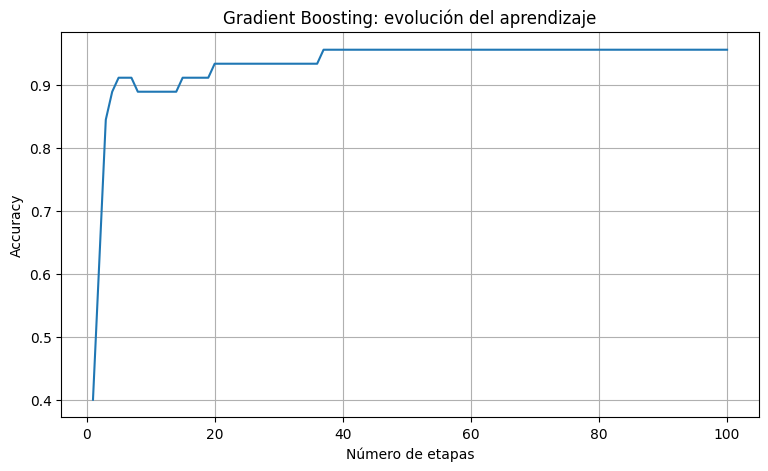

In [ ]:
staged_accuracy = []

for prediction in gradient_boosting.staged_predict(X_test):
    staged_accuracy.append(
        accuracy_score(y_test, prediction)
    )

plt.figure(figsize=(9,5))
plt.plot(
    range(1, len(staged_accuracy) + 1),
    staged_accuracy
)

plt.xlabel("Número de etapas")
plt.ylabel("Accuracy")
plt.title("Gradient Boosting: evolución del aprendizaje")
plt.grid()
plt.show()

## 4. Efecto del learning rate

¿Que es learning rate?
El learning rate (o tasa de aprendizaje) es un hiperparámetro fundamental en los algoritmos de aprendizaje por conjuntos secuenciales, como el aumento de gradiente (gradient boosting). Su función principal es determinar la contribución de cada árbol o aprendiz base al conjunto final
El impacto de este parámetro en el comportamiento y rendimiento del modelo se define por los siguientes aspectos:
1. Control de la influencia (Regularización)
La tasa de aprendizaje forma parte de la etapa de regularización del algoritmo
. Tras calcular los residuos (errores) del modelo anterior, se aplica este parámetro para reducir e influir en la escala de la contribución de cada nuevo aprendiz débil antes de integrarlo al conjunto
. Calibrar esta escala permite controlar directamente la rapidez con la que avanza el algoritmo de impulso
.
2. Efecto de una tasa de aprendizaje pequeña
Menor riesgo de sobreajuste (overfitting): Al limitar el impacto de cada nuevo árbol, se evita que el modelo se adapte con demasiada rapidez al ruido de los datos de entrenamiento, lo que optimiza el rendimiento general y mejora la capacidad de generalización
.
Convergencia más lenta: El aspecto negativo es que ralentiza el proceso de aprendizaje, requiriendo más iteraciones y tiempo de entrenamiento para alcanzar resultados óptimos
.
3. Efecto de una tasa de aprendizaje grande
Entrenamiento más rápido: Permite que el modelo aprenda a una velocidad mayor al permitir que cada árbol aporte una corrección significativa en menos iteraciones
.
Mayor riesgo de sobreajuste: Un valor demasiado alto puede hacer que el modelo se especialice excesivamente en los datos de entrenamiento a expensas de su desempeño con datos no vistos (reduciendo la precisión de validación)
.
En la práctica, ajustar el learning rate requiere equilibrar su valor con el número de árboles (n_estimators), ya que ambos influyen directamente en la complejidad del modelo y el riesgo de sobreajuste
.

In [ ]:
learning_rates = [0.01, 0.05, 0.1, 0.5, 1.0]
lr_scores = []

for lr in learning_rates:
    model = GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=lr,
        max_depth=2,
        random_state=42
    )

    model.fit(X_train, y_train)
    lr_scores.append(model.score(X_test, y_test))

lr_results = pd.DataFrame({
    "learning_rate": learning_rates,
    "accuracy": lr_scores
})

lr_results

,learning_rate,accuracy
0,0.01,0.911111
1,0.05,0.955556
2,0.10,1.000000
3,0.50,0.977778
4,1.00,1.000000


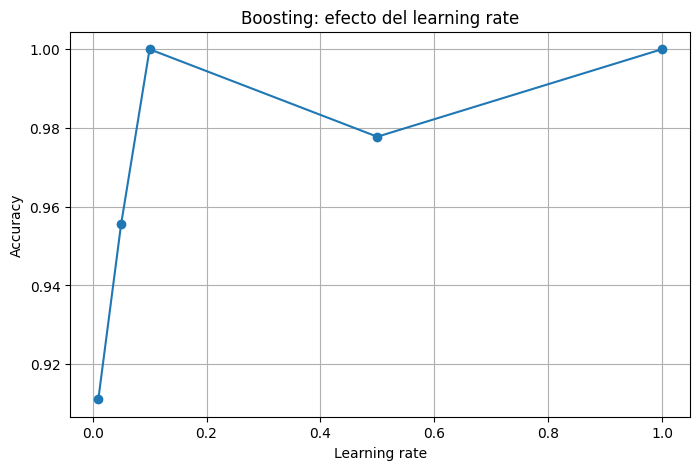

In [ ]:
plt.figure(figsize=(8,5))
plt.plot(
    lr_results["learning_rate"],
    lr_results["accuracy"],
    marker="o"
)

plt.xlabel("Learning rate")
plt.ylabel("Accuracy")
plt.title("Boosting: efecto del learning rate")
plt.grid()
plt.show()

## 5. Comparación ROC

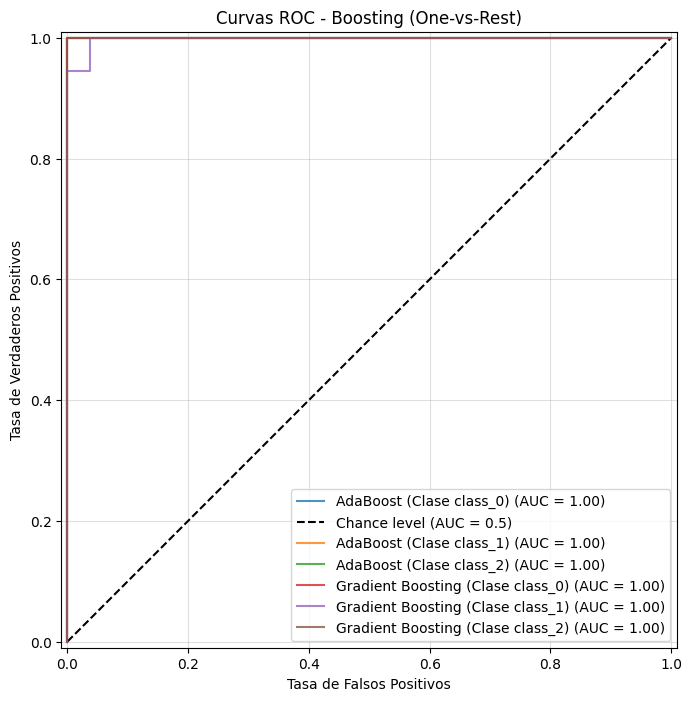

In [ ]:
plt.figure(figsize=(10, 8))
ax = plt.gca()

# Get the class names from the original data object
n_classes = len(data.target_names)
class_names = data.target_names

models = {
    "AdaBoost": adaboost,
    "Gradient Boosting": gradient_boosting
}

# Iterate over each model
for model_name, model in models.items():
    # Get probabilities for all classes
    y_score = model.predict_proba(X_test)

    # Plot ROC curve for each class using OvR strategy
    for i in range(n_classes):
        # Create binary target for current class (1 if it's the current class, 0 otherwise)
        y_test_binary = (y_test == i).astype(int)
        # Get probabilities for the current class
        y_score_class_i = y_score[:, i]

        RocCurveDisplay.from_predictions(
            y_test_binary,
            y_score_class_i,
            name=f"{model_name} (Clase {class_names[i]})",
            ax=ax,
            alpha=0.8,
            # Plot chance level only once to avoid duplicate legends
            plot_chance_level=(i == 0 and model_name == list(models.keys())[0])
        )

plt.title("Curvas ROC - Boosting (One-vs-Rest)")
plt.xlabel("Tasa de Falsos Positivos")
plt.ylabel("Tasa de Verdaderos Positivos")
plt.legend(loc="lower right")
plt.grid(alpha=0.4)
plt.show()

## 6. Métricas finales

In [ ]:
def evaluar_modelo(nombre, modelo, X_test, y_test):
    pred = modelo.predict(X_test)
    prob_all_classes = modelo.predict_proba(X_test)

    return {
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, average='weighted', zero_division=0),
        "Recall": recall_score(y_test, pred, average='weighted', zero_division=0),
        "F1": f1_score(y_test, pred, average='weighted', zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, prob_all_classes, multi_class='ovr', average='weighted')
    }

In [ ]:
resultados = pd.DataFrame([
    evaluar_modelo("AdaBoost", adaboost, X_test, y_test),
    evaluar_modelo("Gradient Boosting", gradient_boosting, X_test, y_test)
])

resultados

,Modelo,Accuracy,Precision,Recall,F1,ROC-AUC
0,AdaBoost,0.977778,0.979167,0.977778,0.977819,1.000000
1,Gradient Boosting,0.955556,0.956944,0.955556,0.955431,0.999177


## Preguntas de análisis

- ¿Qué diferencia conceptual existe entre AdaBoost y Gradient Boosting?
- ¿Por qué Boosting se considera un proceso secuencial?
- ¿Qué efecto tiene un learning rate muy alto?
- ¿Por qué aumentar indefinidamente el número de estimadores no garantiza mejorar el modelo?